In [9]:
import mujoco

model = mujoco.MjModel.from_xml_path(
    "drone-example/mujoco_menagerie-main/skydio_x2/scene.xml"
)
data = mujoco.MjData(model)

print("Cameras:", [model.camera(i).name for i in range(model.ncam)])
print("Sensors:", [model.sensor(i).name for i in range(model.nsensor)])

Cameras: ['track', 'drone_camera']
Sensors: ['body_gyro', 'body_linacc', 'body_quat']


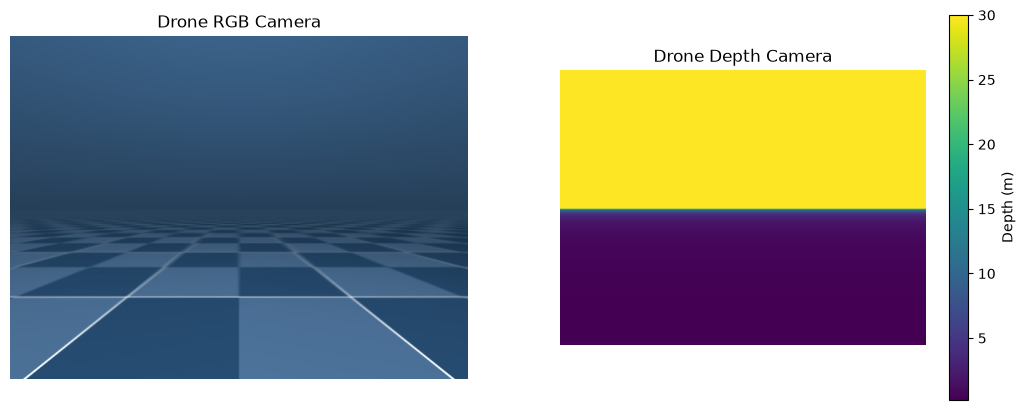

In [10]:
import matplotlib.pyplot as plt
import numpy as np

mujoco.mj_forward(model, data)

renderer = mujoco.Renderer(model, height=480, width=640)

# RGB image
renderer.update_scene(data, camera="drone_camera")
rgb = renderer.render().copy()

# Depth image
renderer.enable_depth_rendering()
renderer.update_scene(data, camera="drone_camera")
depth = renderer.render().copy()
renderer.disable_depth_rendering()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(rgb)
axes[0].set_title("Drone RGB Camera")

im = axes[1].imshow(depth, cmap="viridis")
axes[1].set_title("Drone Depth Camera")
fig.colorbar(im, ax=axes[1], label="Depth (m)")

for ax in axes:
    ax.axis("off")

plt.show()

renderer.close()

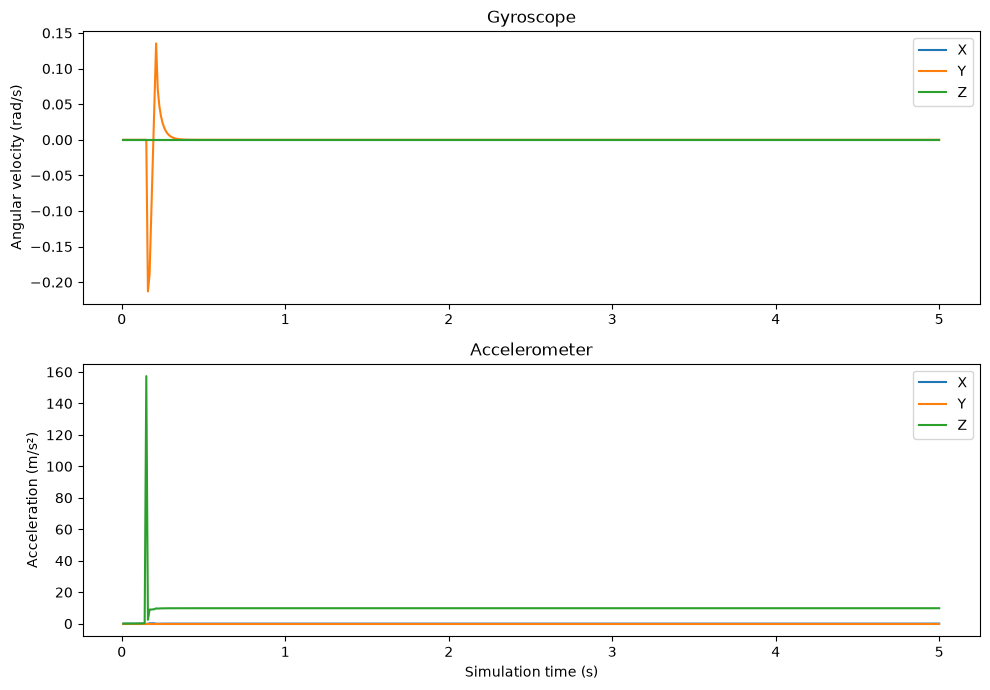

In [11]:
mujoco.mj_resetData(model, data)

times = []
gyro_log = []
accel_log = []

for _ in range(500):
    mujoco.mj_step(model, data)

    times.append(data.time)
    gyro_log.append(data.sensor("body_gyro").data.copy())
    accel_log.append(data.sensor("body_linacc").data.copy())

gyro_log = np.array(gyro_log)
accel_log = np.array(accel_log)
times = np.array(times)

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

for i, axis in enumerate(["X", "Y", "Z"]):
    axes[0].plot(times, gyro_log[:, i], label=axis)
    axes[1].plot(times, accel_log[:, i], label=axis)

axes[0].set_title("Gyroscope")
axes[0].set_ylabel("Angular velocity (rad/s)")
axes[0].legend()

axes[1].set_title("Accelerometer")
axes[1].set_ylabel("Acceleration (m/s²)")
axes[1].set_xlabel("Simulation time (s)")
axes[1].legend()

plt.tight_layout()
plt.show()

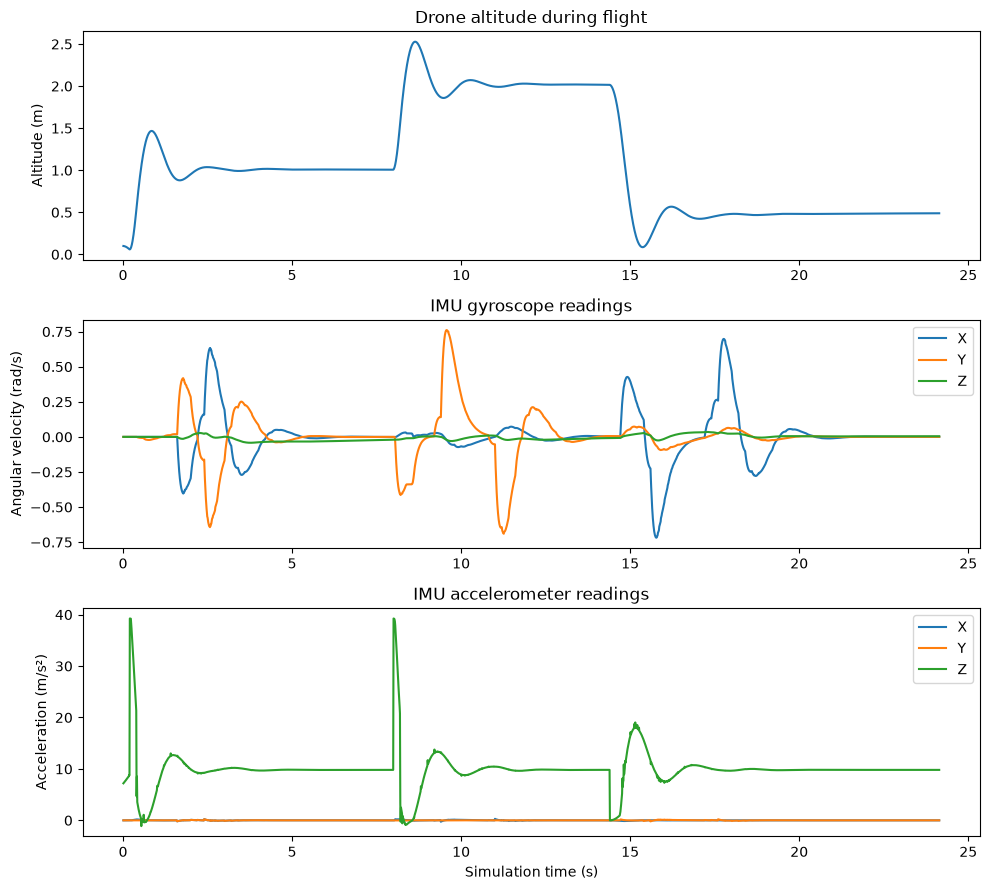

In [13]:
import pandas as pd

df = pd.read_csv(
    "drone-example/sensor_outputs/imu_data.csv"
)

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

# Drone altitude
axes[0].plot(df["time"], df["z"])
axes[0].set_ylabel("Altitude (m)")
axes[0].set_title("Drone altitude during flight")

# Gyroscope
for axis in ["x", "y", "z"]:
    axes[1].plot(
        df["time"],
        df[f"gyro_{axis}"],
        label=axis.upper()
    )
axes[1].set_ylabel("Angular velocity (rad/s)")
axes[1].set_title("IMU gyroscope readings")
axes[1].legend()

# Accelerometer
for axis in ["x", "y", "z"]:
    axes[2].plot(
        df["time"],
        df[f"accel_{axis}"],
        label=axis.upper()
    )
axes[2].set_ylabel("Acceleration (m/s²)")
axes[2].set_xlabel("Simulation time (s)")
axes[2].set_title("IMU accelerometer readings")
axes[2].legend()

plt.tight_layout()
plt.show()

In [14]:
from IPython.display import Video, display

display(Video(
    "drone-example/sensor_outputs/drone_rgb.mp4",
    embed=True
))

Depth array shape: (120, 240, 320)


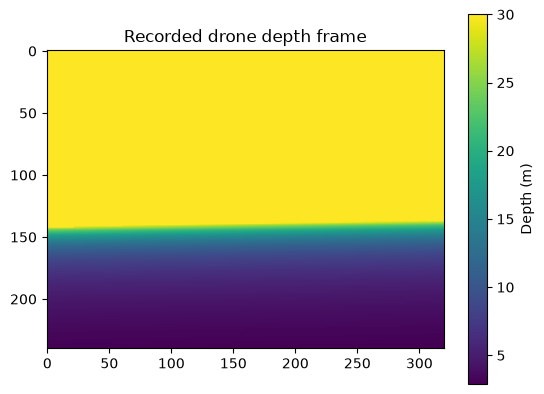

In [15]:
recording = np.load(
    "drone-example/sensor_outputs/depth_frames.npz"
)

depth = recording["depth"]
print("Depth array shape:", depth.shape)

plt.imshow(depth[len(depth) // 2], cmap="viridis")
plt.colorbar(label="Depth (m)")
plt.title("Recorded drone depth frame")
plt.show()

Total depth frames: 120
Frame dimensions: (240, 320)
Recorded duration: 23.800000000000953 seconds


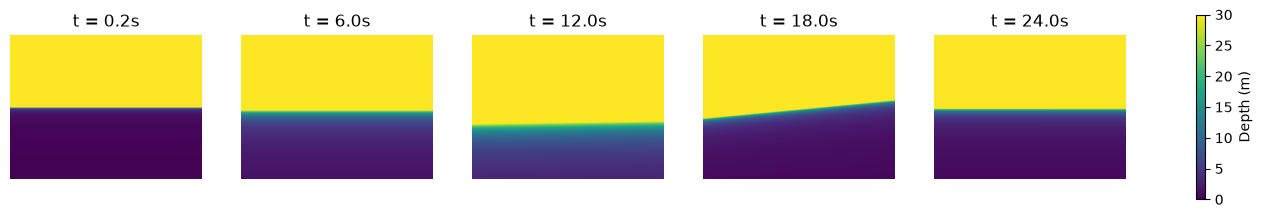

In [16]:
recording = np.load(
    "drone-example/sensor_outputs/depth_frames.npz"
)

depth_frames = recording["depth"]
timestamps = recording["timestamps"]

print("Total depth frames:", len(depth_frames))
print("Frame dimensions:", depth_frames.shape[1:])
print("Recorded duration:", timestamps[-1] - timestamps[0], "seconds")

# Select five frames throughout the flight
indices = np.linspace(
    0, len(depth_frames) - 1, 5, dtype=int
)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, idx in zip(axes, indices):
    im = ax.imshow(
        depth_frames[idx],
        cmap="viridis",
        vmin=0,
        vmax=30
    )
    ax.set_title(f"t = {timestamps[idx]:.1f}s")
    ax.axis("off")

fig.colorbar(im, ax=axes, label="Depth (m)", shrink=0.6)
plt.show()

In [17]:
import imageio.v2 as imageio

# Load depth frames saved by main_sensors.py
recording = np.load(
    "drone-example/sensor_outputs/depth_frames.npz"
)

depth_frames = recording["depth"]
timestamps = recording["timestamps"]

# Convert depth values to colored images
frames = []

for depth in depth_frames:
    normalized = np.clip(depth / 30.0, 0, 1)
    colored = plt.get_cmap("viridis")(normalized)
    colored = (colored[:, :, :3] * 255).astype(np.uint8)
    frames.append(colored)

# Calculate FPS from simulation timestamps
fps = 1 / np.median(np.diff(timestamps))

# Save the video
video_path = "drone-example/sensor_outputs/drone_depth.mp4"
imageio.mimsave(video_path, frames, fps=fps)

# Display it in Jupyter
display(Video(video_path, embed=True))